In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU detected!")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


In [ ]:
!git clone -b transfer-learning https://github.com/OmarAbouraia/From-Pixels-to-Language.git

Cloning into 'From-Pixels-to-Language'...
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (50/50), done.
remote: Total 69 (delta 15), reused 57 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (69/69), 21.82 MiB | 20.42 MiB/s, done.
Resolving deltas: 100% (15/15), done.


In [ ]:
%cd From-Pixels-to-Language
!git branch --show-current
!ls

[Errno 2] No such file or directory: 'From-Pixels-to-Language'
/content/From-Pixels-to-Language
transfer-learning
docs  outputs  README.md  requirements.txt  src  tests


In [ ]:
!pip install -r requirements.txt

In [ ]:
import torch
import torchvision
import datasets
import sklearn

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Datasets:", datasets.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Datasets: 4.8.5
CUDA available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DRIVE_ROOT = "/content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning"

os.makedirs(DRIVE_ROOT, exist_ok=True)

print("Drive directory:", DRIVE_ROOT)
print("Directory exists:", os.path.exists(DRIVE_ROOT))

Drive directory: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning
Directory exists: True


In [ ]:
from src.transfer_learning.data import create_transfer_learning_loaders

# Create DataLoaders using the original EDA split
train_loader, val_loader = create_transfer_learning_loaders(
    batch_size=32,
    num_workers=2
)

print("Training samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))

# Inspect one training batch
batch = next(iter(train_loader))

images = batch["image"]
labels = batch["label"]

print("\nBatch verification:")
print("Images shape:", images.shape)
print("Images dtype:", images.dtype)
print("Labels shape:", labels.shape)
print("Labels dtype:", labels.dtype)
print("Minimum label:", labels.min().item())
print("Maximum label:", labels.max().item())
print("Unique labels in batch:", labels.unique().numel())

README.md:   0%|          | 0.00/7.16k [00:00<?, ?B/s]

data/train-00000-of-00002-5e7d350dbc117c(…): reconstructing file:   0%|          |  0.00B /  287MB            

data/train-00000-of-00002-5e7d350dbc117c(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-ae08e95fea856c(…): reconstructing file:   0%|          |  0.00B /  297MB            

data/train-00001-of-00002-ae08e95fea856c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5994 [00:00<?, ? examples/s]

Training samples: 4795
Validation samples: 1198

Batch verification:
Images shape: torch.Size([32, 3, 224, 224])
Images dtype: torch.float32
Labels shape: torch.Size([32])
Labels dtype: torch.int64
Minimum label: 5
Maximum label: 191
Unique labels in batch: 29


In [ ]:
import torch

all_train_labels = torch.cat([
    batch["label"] for batch in train_loader
])

all_val_labels = torch.cat([
    batch["label"] for batch in val_loader
])

all_labels = torch.cat([all_train_labels, all_val_labels])

print("Minimum label:", all_labels.min().item())
print("Maximum label:", all_labels.max().item())
print("Number of unique classes:", all_labels.unique().numel())

assert all_labels.min().item() >= 0
assert all_labels.max().item() < 200
assert all_labels.unique().numel() == 200

print("\nAll label checks passed!")

Minimum label: 0
Maximum label: 199
Number of unique classes: 200

All label checks passed!


In [ ]:
import torch
from src.transfer_learning.model import create_resnet18

# Select GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create pretrained ResNet18 in Feature Extraction mode
model = create_resnet18(
    num_classes=200,
    mode="feature_extraction",
    pretrained=True
).to(device)

# Get one batch
batch = next(iter(train_loader))
images = batch["image"].to(device)
labels = batch["label"].to(device)

# Forward pass
model.eval()

with torch.no_grad():
    outputs = model(images)

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Output dtype:", outputs.dtype)

# Verify output
assert outputs.shape == (32, 200)

print("\nGPU forward pass successful!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


Device: cuda
GPU: Tesla T4
Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 200])
Output dtype: torch.float32

GPU forward pass successful!


In [ ]:
import os

FEATURE_EXTRACTION_DIR = os.path.join(
    DRIVE_ROOT,
    "Feature-Extraction"
)

os.makedirs(
    os.path.join(FEATURE_EXTRACTION_DIR, "Checkpoints"),
    exist_ok=True
)

os.makedirs(
    os.path.join(FEATURE_EXTRACTION_DIR, "Logs"),
    exist_ok=True
)

os.makedirs(
    os.path.join(FEATURE_EXTRACTION_DIR, "Plots"),
    exist_ok=True
)

print("Feature Extraction output directory:")
print(FEATURE_EXTRACTION_DIR)

print("\nCreated directories:")
for folder in ["Checkpoints", "Logs", "Plots"]:
    print(f" - {folder}")

Feature Extraction output directory:
/content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Feature-Extraction

Created directories:
 - Checkpoints
 - Logs
 - Plots


In [ ]:
!python -m src.transfer_learning.train \
    --mode feature_extraction \
    --epochs 10 \
    --batch-size 32 \
    --learning-rate 0.001 \
    --num-workers 2 \
    --output-dir "{FEATURE_EXTRACTION_DIR}"

TRANSFER LEARNING EXPERIMENT
Mode: feature_extraction
Device: cuda
Epochs: 10
Batch Size: 32
Learning Rate: 0.001

Loading dataset...
Training samples: 4795
Validation samples: 1198

Initializing ResNet18...

Epoch [1/10]
----------------------------------------
Train Loss: 4.4763 | Train Accuracy: 0.1293
Val Loss:   3.4376 | Val Accuracy: 0.2604
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [2/10]
----------------------------------------
Train Loss: 2.7252 | Train Accuracy: 0.4380
Val Loss:   2.6257 | Val Accuracy: 0.4065
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [3/10]
----------------------------------------
Train Loss: 1.9978 | Train Accuracy: 0.5779
Val Loss:   2.2447 | Val Accuracy: 0.4558
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [4/10]
----------------------------------------
Train Loss: 1.5734 | Train Accuracy: 0.6747
Val Loss:   2.0680 | Val Accur

In [ ]:
import os
import torch
import pandas as pd

DRIVE_ROOT = "/content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning"

FEATURE_EXTRACTION_DIR = os.path.join(
    DRIVE_ROOT,
    "Feature-Extraction"
)

CHECKPOINT_PATH = os.path.join(
    FEATURE_EXTRACTION_DIR,
    "best_model.pth"
)

HISTORY_PATH = os.path.join(
    FEATURE_EXTRACTION_DIR,
    "training_history.csv"
)

print("Checkpoint exists:", os.path.exists(CHECKPOINT_PATH))
print("Training history exists:", os.path.exists(HISTORY_PATH))

Checkpoint exists: True
Training history exists: True


In [ ]:
import torch

checkpoint = torch.load(
    os.path.join(FEATURE_EXTRACTION_DIR, "best_model.pth"),
    map_location="cpu"
)

print("Checkpoint keys:")
for key, value in checkpoint.items():
    print(f"{key}: {type(value)}")

print("\nBest epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

Checkpoint keys:
epoch: <class 'int'>
model_state_dict: <class 'collections.OrderedDict'>
optimizer_state_dict: <class 'dict'>
best_val_loss: <class 'float'>
mode: <class 'str'>
learning_rate: <class 'float'>
batch_size: <class 'int'>

Best epoch: 10
Best validation loss: 1.668891964054267


In [ ]:
import os

PROJECT_DIR = "/content/From-Pixels-to-Language"

print("Repository exists:", os.path.exists(PROJECT_DIR))

Repository exists: False


In [ ]:
!git clone -b transfer-learning https://github.com/OmarAbouraia/From-Pixels-to-Language.git

Cloning into 'From-Pixels-to-Language'...
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (50/50), done.
remote: Total 69 (delta 15), reused 57 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (69/69), 21.82 MiB | 20.24 MiB/s, done.
Resolving deltas: 100% (15/15), done.


In [ ]:
%cd /content/From-Pixels-to-Language

/content/From-Pixels-to-Language


In [ ]:
from src.transfer_learning.data import create_transfer_learning_loaders

train_loader, val_loader = create_transfer_learning_loaders(
    batch_size=32,
    num_workers=2
)

print("Training samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))

README.md:   0%|          | 0.00/7.16k [00:00<?, ?B/s]

data/train-00000-of-00002-5e7d350dbc117c(…): reconstructing file:   0%|          |  0.00B /  287MB            

data/train-00000-of-00002-5e7d350dbc117c(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-ae08e95fea856c(…): reconstructing file:   0%|          |  0.00B /  297MB            

data/train-00001-of-00002-ae08e95fea856c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5994 [00:00<?, ? examples/s]

Training samples: 4795
Validation samples: 1198


In [ ]:
from src.transfer_learning.model import create_resnet18

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = create_resnet18(
    num_classes=200,
    mode="feature_extraction",
    pretrained=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Mode:", checkpoint["mode"])
print("Best epoch:", checkpoint["epoch"])

Model loaded successfully!
Device: cuda
Mode: feature_extraction
Best epoch: 10


In [ ]:
import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# Store predictions and actual labels
all_predictions = []
all_targets = []

model.eval()

with torch.no_grad():

    for batch in val_loader:

        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        outputs = model(images)

        # Top-1 predictions
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

        # Collect top-5 predictions
        if "all_top5" not in locals():
            all_top5 = []

        top5 = outputs.topk(5, dim=1).indices
        all_top5.extend(top5.cpu().numpy())

# Convert to NumPy arrays
y_true = np.array(all_targets)
y_pred = np.array(all_predictions)
y_top5 = np.array(all_top5)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
)

top5_accuracy = np.mean([
    target in predictions
    for target, predictions in zip(y_true, y_top5)
])

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(200)
)

# Display results
print("=" * 50)
print("FEATURE EXTRACTION - VALIDATION RESULTS")
print("=" * 50)

print(f"Accuracy:           {accuracy:.4f}")
print(f"Top-5 Accuracy:     {top5_accuracy:.4f}")

print("\nMacro Average:")
print(f"Precision:          {macro_precision:.4f}")
print(f"Recall:             {macro_recall:.4f}")
print(f"F1-score:           {macro_f1:.4f}")

print("\nWeighted Average:")
print(f"Precision:          {weighted_precision:.4f}")
print(f"Recall:             {weighted_recall:.4f}")
print(f"F1-score:           {weighted_f1:.4f}")

print("\nConfusion Matrix Shape:", cm.shape)

FEATURE EXTRACTION - VALIDATION RESULTS
Accuracy:           0.5476
Top-5 Accuracy:     0.8481

Macro Average:
Precision:          0.5873
Recall:             0.5473
F1-score:           0.5392

Weighted Average:
Precision:          0.5875
Recall:             0.5476
F1-score:           0.5394

Confusion Matrix Shape: (200, 200)


In [ ]:
# Save confusion matrix
cm_path = os.path.join(
    FEATURE_EXTRACTION_DIR,
    "confusion_matrix.csv"
)

pd.DataFrame(cm).to_csv(cm_path, index=False)

# Save predictions
predictions_df = pd.DataFrame({
    "actual_label": y_true,
    "predicted_label": y_pred
})

predictions_path = os.path.join(
    FEATURE_EXTRACTION_DIR,
    "validation_predictions.csv"
)

predictions_df.to_csv(predictions_path, index=False)

print("Evaluation artifacts saved successfully!")
print("Confusion Matrix:", cm_path)
print("Predictions:", predictions_path)

Evaluation artifacts saved successfully!
Confusion Matrix: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Feature-Extraction/confusion_matrix.csv
Predictions: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Feature-Extraction/validation_predictions.csv


In [ ]:
import json

feature_extraction_metrics = {
    "experiment": "Feature Extraction",
    "architecture": "ResNet18",
    "pretrained": "ImageNet",
    "epochs": 10,
    "batch_size": 32,
    "learning_rate": 0.001,
    "best_epoch": 10,
    "best_validation_loss": 1.6689,
    "accuracy": 0.5476,
    "top5_accuracy": 0.8481,
    "macro_precision": 0.5873,
    "macro_recall": 0.5473,
    "macro_f1": 0.5392,
    "weighted_precision": 0.5875,
    "weighted_recall": 0.5476,
    "weighted_f1": 0.5394
}

metrics_path = os.path.join(
    FEATURE_EXTRACTION_DIR,
    "evaluation_metrics.json"
)

with open(metrics_path, "w") as file:
    json.dump(feature_extraction_metrics, file, indent=4)

print("Baseline metrics saved:", metrics_path)

Baseline metrics saved: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Feature-Extraction/evaluation_metrics.json


In [ ]:
import os
import json

metrics_path = os.path.join(
    FEATURE_EXTRACTION_DIR,
    "evaluation_metrics.json"
)

print("Metrics file exists:", os.path.exists(metrics_path))

if os.path.exists(metrics_path):
    with open(metrics_path, "r") as f:
        print(json.dumps(json.load(f), indent=4))

Metrics file exists: True
{
    "experiment": "Feature Extraction",
    "architecture": "ResNet18",
    "pretrained": "ImageNet",
    "epochs": 10,
    "batch_size": 32,
    "learning_rate": 0.001,
    "best_epoch": 10,
    "best_validation_loss": 1.6689,
    "accuracy": 0.5476,
    "top5_accuracy": 0.8481,
    "macro_precision": 0.5873,
    "macro_recall": 0.5473,
    "macro_f1": 0.5392,
    "weighted_precision": 0.5875,
    "weighted_recall": 0.5476,
    "weighted_f1": 0.5394
}


In [ ]:
import os

FINE_TUNING_DIR = os.path.join(
    DRIVE_ROOT,
    "Fine-Tuning"
)

os.makedirs(os.path.join(FINE_TUNING_DIR, "Checkpoints"), exist_ok=True)
os.makedirs(os.path.join(FINE_TUNING_DIR, "Logs"), exist_ok=True)
os.makedirs(os.path.join(FINE_TUNING_DIR, "Plots"), exist_ok=True)

print("Fine-Tuning directory:", FINE_TUNING_DIR)

for folder in ["Checkpoints", "Logs", "Plots"]:
    path = os.path.join(FINE_TUNING_DIR, folder)
    print(f"{folder}: {os.path.exists(path)}")

Fine-Tuning directory: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Fine-Tuning
Checkpoints: True
Logs: True
Plots: True


In [ ]:
from src.transfer_learning.model import create_resnet18

test_model = create_resnet18(
    num_classes=200,
    mode="fine_tuning",
    pretrained=True
)

total_params = sum(p.numel() for p in test_model.parameters())
trainable_params = sum(
    p.numel() for p in test_model.parameters() if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("All parameters trainable:", total_params == trainable_params)
print("Classifier output:", test_model.fc.out_features)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 98.0MB/s]


Total parameters: 11,279,112
Trainable parameters: 11,279,112
All parameters trainable: True
Classifier output: 200


In [ ]:
!python -m src.transfer_learning.train \
    --mode fine_tuning \
    --epochs 10 \
    --batch-size 32 \
    --learning-rate 0.0001 \
    --num-workers 2 \
    --output-dir "{FINE_TUNING_DIR}"

TRANSFER LEARNING EXPERIMENT
Mode: fine_tuning
Device: cuda
Epochs: 10
Batch Size: 32
Learning Rate: 0.0001

Loading dataset...
Training samples: 4795
Validation samples: 1198

Initializing ResNet18...

Epoch [1/10]
----------------------------------------
Train Loss: 4.5798 | Train Accuracy: 0.1283
Val Loss:   3.5073 | Val Accuracy: 0.3356
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [2/10]
----------------------------------------
Train Loss: 3.0492 | Train Accuracy: 0.4815
Val Loss:   2.6656 | Val Accuracy: 0.4917
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [3/10]
----------------------------------------
Train Loss: 2.1313 | Train Accuracy: 0.6776
Val Loss:   2.0878 | Val Accuracy: 0.5801
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [4/10]
----------------------------------------
Train Loss: 1.4886 | Train Accuracy: 0.7910
Val Loss:   1.7659 | Val Accuracy: 0

In [ ]:
import os
import torch

from src.transfer_learning.model import create_resnet18

# Checkpoint path
FINE_TUNING_CHECKPOINT = os.path.join(
    FINE_TUNING_DIR,
    "best_model.pth"
)

# Load checkpoint
checkpoint = torch.load(
    FINE_TUNING_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

# Recreate model architecture
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

fine_tuning_model = create_resnet18(
    num_classes=200,
    mode="fine_tuning",
    pretrained=False
)

# Restore trained weights
fine_tuning_model.load_state_dict(
    checkpoint["model_state_dict"]
)

fine_tuning_model = fine_tuning_model.to(device)
fine_tuning_model.eval()

print("\nModel restored successfully!")
print("Device:", device)
print("Output classes:", fine_tuning_model.fc.out_features)

Checkpoint loaded successfully!
Best epoch: 10
Best validation loss: 1.311623202142413

Model restored successfully!
Device: cuda
Output classes: 200


In [ ]:
import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

fine_tuning_model.eval()

all_predictions = []
all_targets = []
all_top5 = []

with torch.no_grad():
    for batch in val_loader:

        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        outputs = fine_tuning_model(images)

        # Top-1 predictions
        predictions = outputs.argmax(dim=1)

        # Top-5 predictions
        top5_predictions = outputs.topk(5, dim=1).indices

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())
        all_top5.extend(top5_predictions.cpu().numpy())

# Convert to NumPy arrays
y_true_ft = np.array(all_targets)
y_pred_ft = np.array(all_predictions)
y_top5_ft = np.array(all_top5)

# Top-1 Accuracy
accuracy_ft = accuracy_score(y_true_ft, y_pred_ft)

# Top-5 Accuracy
top5_accuracy_ft = np.mean([
    target in predictions
    for target, predictions in zip(y_true_ft, y_top5_ft)
])

# Macro metrics
macro_precision_ft, macro_recall_ft, macro_f1_ft, _ = (
    precision_recall_fscore_support(
        y_true_ft,
        y_pred_ft,
        average="macro",
        zero_division=0
    )
)

# Weighted metrics
weighted_precision_ft, weighted_recall_ft, weighted_f1_ft, _ = (
    precision_recall_fscore_support(
        y_true_ft,
        y_pred_ft,
        average="weighted",
        zero_division=0
    )
)

# Confusion Matrix
cm_ft = confusion_matrix(
    y_true_ft,
    y_pred_ft,
    labels=np.arange(200)
)

# Display results
print("=" * 55)
print("FINE-TUNING EVALUATION RESULTS")
print("=" * 55)

print(f"Accuracy:          {accuracy_ft:.4f} ({accuracy_ft*100:.2f}%)")
print(f"Top-5 Accuracy:    {top5_accuracy_ft:.4f} ({top5_accuracy_ft*100:.2f}%)")

print("\nMacro Average:")
print(f"Precision:         {macro_precision_ft:.4f}")
print(f"Recall:            {macro_recall_ft:.4f}")
print(f"F1-score:          {macro_f1_ft:.4f}")

print("\nWeighted Average:")
print(f"Precision:         {weighted_precision_ft:.4f}")
print(f"Recall:            {weighted_recall_ft:.4f}")
print(f"F1-score:          {weighted_f1_ft:.4f}")

print("\nConfusion Matrix Shape:", cm_ft.shape)

print("=" * 55)

FINE-TUNING EVALUATION RESULTS
Accuracy:          0.6770 (67.70%)
Top-5 Accuracy:    0.9090 (90.90%)

Macro Average:
Precision:         0.7087
Recall:            0.6768
F1-score:          0.6748

Weighted Average:
Precision:         0.7089
Recall:            0.6770
F1-score:          0.6749

Confusion Matrix Shape: (200, 200)


In [ ]:
import os
import json

fine_tuning_metrics = {
    "experiment": "Fine-Tuning",
    "architecture": "ResNet18",
    "pretrained": "ImageNet",
    "epochs": 10,
    "batch_size": 32,
    "learning_rate": 0.0001,
    "best_epoch": 10,
    "best_validation_loss": 1.3116,
    "accuracy": float(accuracy_ft),
    "top5_accuracy": float(top5_accuracy_ft),
    "macro_precision": float(macro_precision_ft),
    "macro_recall": float(macro_recall_ft),
    "macro_f1": float(macro_f1_ft),
    "weighted_precision": float(weighted_precision_ft),
    "weighted_recall": float(weighted_recall_ft),
    "weighted_f1": float(weighted_f1_ft)
}

metrics_path = os.path.join(
    FINE_TUNING_DIR,
    "evaluation_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(fine_tuning_metrics, f, indent=4)

print("Evaluation metrics saved:", metrics_path)

Evaluation metrics saved: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Fine-Tuning/evaluation_metrics.json


In [ ]:
import pandas as pd

# Save confusion matrix
cm_path = os.path.join(
    FINE_TUNING_DIR,
    "confusion_matrix.csv"
)

pd.DataFrame(cm_ft).to_csv(cm_path, index=False)

# Save validation predictions
predictions_df = pd.DataFrame({
    "true_label": y_true_ft,
    "predicted_label": y_pred_ft,
    "correct": y_true_ft == y_pred_ft
})

predictions_path = os.path.join(
    FINE_TUNING_DIR,
    "validation_predictions.csv"
)

predictions_df.to_csv(predictions_path, index=False)

print("Confusion matrix saved:", cm_path)
print("Predictions saved:", predictions_path)

Confusion matrix saved: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Fine-Tuning/confusion_matrix.csv
Predictions saved: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Fine-Tuning/validation_predictions.csv


In [ ]:
import pandas as pd
import os

FEATURE_HISTORY = os.path.join(
    FEATURE_EXTRACTION_DIR,
    "training_history.csv"
)

FINE_TUNING_HISTORY = os.path.join(
    FINE_TUNING_DIR,
    "training_history.csv"
)

fe_history = pd.read_csv(FEATURE_HISTORY)
ft_history = pd.read_csv(FINE_TUNING_HISTORY)

print("FEATURE EXTRACTION")
print(fe_history.columns.tolist())
display(fe_history.head())

print("\nFINE-TUNING")
print(ft_history.columns.tolist())
display(ft_history.head())

FEATURE EXTRACTION
['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy']


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,4.476282,0.129301,3.437589,0.260434
1,2,2.725221,0.437956,2.625654,0.406511
2,3,1.997761,0.577894,2.244746,0.455760
3,4,1.573436,0.674661,2.068009,0.476628
4,5,1.329619,0.725339,1.906141,0.505843



FINE-TUNING
['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy']


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,4.579796,0.128259,3.507338,0.335559
1,2,3.049202,0.481543,2.665580,0.491653
2,3,2.131287,0.677581,2.087845,0.580134
3,4,1.488553,0.791032,1.765902,0.630217
4,5,1.034136,0.866319,1.597872,0.638564


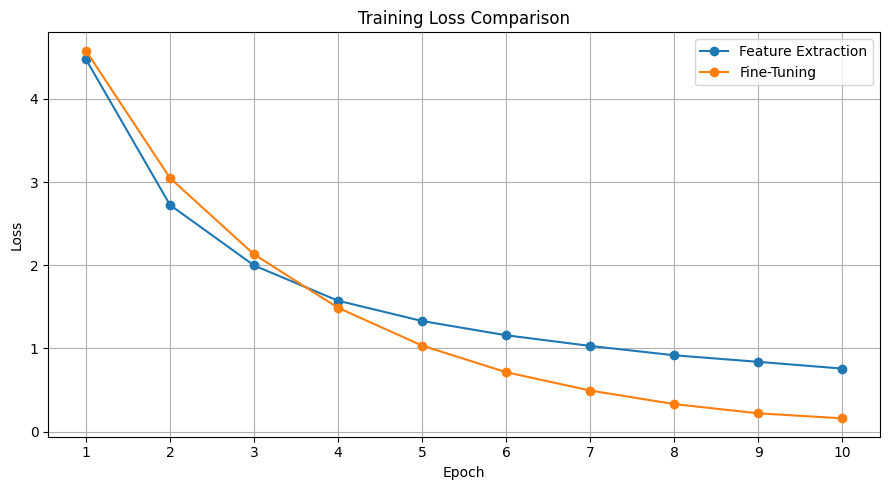

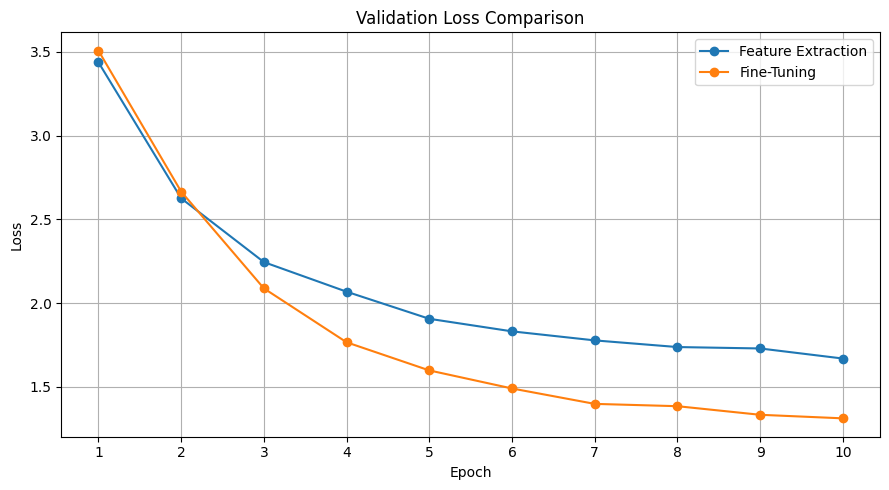

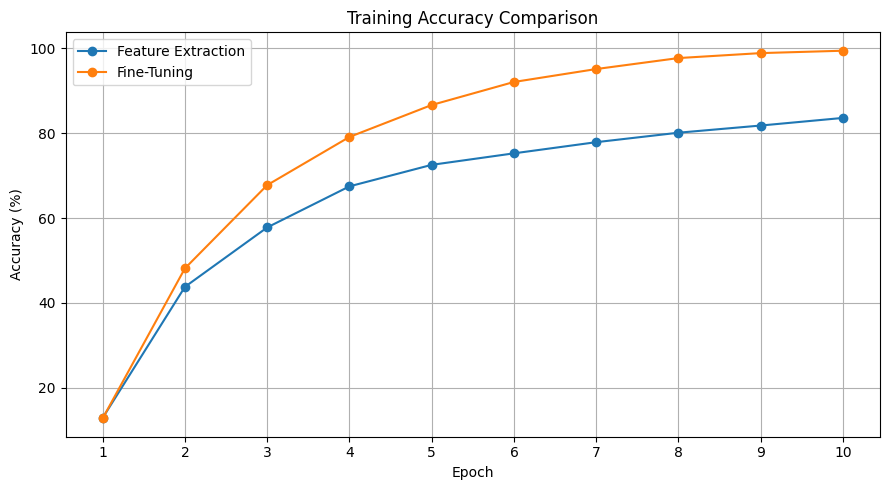

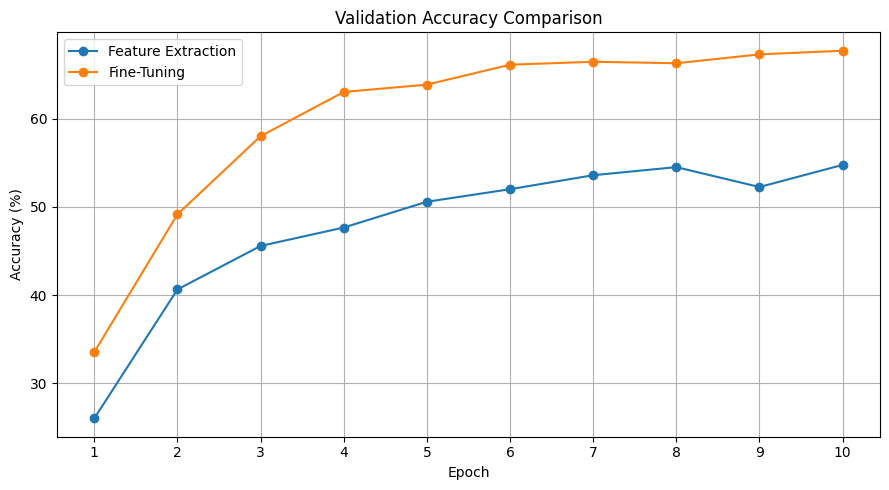

All four plots saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import os

# Plot configuration
epochs = fe_history["epoch"]

# 1. Training Loss
plt.figure(figsize=(9, 5))

plt.plot(epochs, fe_history["train_loss"], marker="o", label="Feature Extraction")
plt.plot(epochs, ft_history["train_loss"], marker="o", label="Fine-Tuning")

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(FINE_TUNING_DIR, "Plots", "training_loss_comparison.png"),
    dpi=300
)
plt.show()


# 2. Validation Loss
plt.figure(figsize=(9, 5))

plt.plot(epochs, fe_history["val_loss"], marker="o", label="Feature Extraction")
plt.plot(epochs, ft_history["val_loss"], marker="o", label="Fine-Tuning")

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(FINE_TUNING_DIR, "Plots", "validation_loss_comparison.png"),
    dpi=300
)
plt.show()


# 3. Training Accuracy
plt.figure(figsize=(9, 5))

plt.plot(epochs, fe_history["train_accuracy"] * 100, marker="o", label="Feature Extraction")
plt.plot(epochs, ft_history["train_accuracy"] * 100, marker="o", label="Fine-Tuning")

plt.title("Training Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(FINE_TUNING_DIR, "Plots", "training_accuracy_comparison.png"),
    dpi=300
)
plt.show()


# 4. Validation Accuracy
plt.figure(figsize=(9, 5))

plt.plot(epochs, fe_history["val_accuracy"] * 100, marker="o", label="Feature Extraction")
plt.plot(epochs, ft_history["val_accuracy"] * 100, marker="o", label="Fine-Tuning")

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(FINE_TUNING_DIR, "Plots", "validation_accuracy_comparison.png"),
    dpi=300
)
plt.show()

print("All four plots saved successfully!")

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

# Class-wise metrics
class_report = classification_report(
    y_true_ft,
    y_pred_ft,
    labels=np.arange(200),
    output_dict=True,
    zero_division=0
)

class_metrics = pd.DataFrame(class_report).T
class_metrics = class_metrics.iloc[:200].copy()

class_metrics.index = class_metrics.index.astype(int)
class_metrics.index.name = "class_id"

# Calculate correctly and incorrectly classified samples
class_metrics["support"] = class_metrics["support"].astype(int)
class_metrics["correct"] = cm_ft.diagonal()
class_metrics["incorrect"] = (
    class_metrics["support"] - class_metrics["correct"]
)

# Sort by recall to identify the weakest classes
weakest_classes = class_metrics.sort_values(
    "recall", ascending=True
)

print("10 Classes with Lowest Recall:")
display(
    weakest_classes[
        ["precision", "recall", "f1-score", "support", "correct", "incorrect"]
    ].head(10)
)

print("\n10 Classes with Highest Recall:")
display(
    class_metrics.sort_values("recall", ascending=False)[
        ["precision", "recall", "f1-score", "support", "correct", "incorrect"]
    ].head(10)
)

10 Classes with Lowest Recall:


,precision,recall,f1-score,support,correct,incorrect
class_id,,,,,,
28,0.000000,0.000000,0.000000,6,0,6
48,0.000000,0.000000,0.000000,6,0,6
114,0.000000,0.000000,0.000000,6,0,6
29,0.333333,0.166667,0.222222,6,1,5
36,0.333333,0.166667,0.222222,6,1,5
61,1.000000,0.166667,0.285714,6,1,5
115,0.500000,0.166667,0.250000,6,1,5
26,0.076923,0.166667,0.105263,6,1,5
125,0.500000,0.166667,0.250000,6,1,5



10 Classes with Highest Recall:


,precision,recall,f1-score,support,correct,incorrect
class_id,,,,,,
0,0.375000,1.0,0.545455,6,6,0
35,0.750000,1.0,0.857143,6,6,0
34,0.857143,1.0,0.923077,6,6,0
33,1.000000,1.0,1.000000,6,6,0
16,1.000000,1.0,1.000000,6,6,0
17,1.000000,1.0,1.000000,6,6,0
11,1.000000,1.0,1.000000,6,6,0
9,1.000000,1.0,1.000000,6,6,0
56,1.000000,1.0,1.000000,6,6,0


In [ ]:
import numpy as np
import pandas as pd

# Copy confusion matrix and remove diagonal
cm_off_diagonal = cm_ft.copy()
np.fill_diagonal(cm_off_diagonal, 0)

# Find the most frequent misclassification pairs
misclassification_pairs = []

for true_class in range(200):
    for predicted_class in range(200):
        count = cm_off_diagonal[true_class, predicted_class]

        if count > 0:
            misclassification_pairs.append({
                "actual_class": true_class,
                "predicted_class": predicted_class,
                "misclassified_samples": int(count)
            })

pairs_df = pd.DataFrame(misclassification_pairs)

pairs_df = pairs_df.sort_values(
    "misclassified_samples",
    ascending=False
).reset_index(drop=True)

print("Top 20 Misclassification Pairs:")
display(pairs_df.head(20))

Top 20 Misclassification Pairs:


,actual_class,predicted_class,misclassified_samples
0,135,136,4
1,48,26,3
2,122,123,3
3,152,154,3
4,66,67,3
5,106,107,3
6,83,143,3
7,114,130,3
8,32,30,3
9,171,161,3


In [ ]:
dataset = train_loader.dataset.dataset

print("Dataset features:")
print(dataset.features)

print("\nLabel feature:")
print(dataset.features["label"])

# Check whether Hugging Face provides class names
if hasattr(dataset.features["label"], "names"):
    class_names = dataset.features["label"].names

    print("\nNumber of classes:", len(class_names))
    print("\nFirst 10 classes:")

    for i, name in enumerate(class_names[:10]):
        print(f"{i}: {name}")
else:
    print("\nNo class names found in the label feature.")

Dataset features:
{'image': Image(mode=None, decode=True), 'description': Value('string'), 'label': ClassLabel(names=['Black footed Albatross', 'Laysan Albatross', 'Sooty Albatross', 'Groove billed Ani', 'Crested Auklet', 'Least Auklet', 'Parakeet Auklet', 'Rhinoceros Auklet', 'Brewer Blackbird', 'Red winged Blackbird', 'Rusty Blackbird', 'Yellow headed Blackbird', 'Bobolink', 'Indigo Bunting', 'Lazuli Bunting', 'Painted Bunting', 'Cardinal', 'Spotted Catbird', 'Gray Catbird', 'Yellow breasted Chat', 'Eastern Towhee', 'Chuck will Widow', 'Brandt Cormorant', 'Red faced Cormorant', 'Pelagic Cormorant', 'Bronzed Cowbird', 'Shiny Cowbird', 'Brown Creeper', 'American Crow', 'Fish Crow', 'Black billed Cuckoo', 'Mangrove Cuckoo', 'Yellow billed Cuckoo', 'Gray crowned Rosy Finch', 'Purple Finch', 'Northern Flicker', 'Acadian Flycatcher', 'Great Crested Flycatcher', 'Least Flycatcher', 'Olive sided Flycatcher', 'Scissor tailed Flycatcher', 'Vermilion Flycatcher', 'Yellow bellied Flycatcher', 'F

In [ ]:
# Add actual bird species names to the misclassification pairs

pairs_named = pairs_df.copy()

pairs_named["actual_species"] = pairs_named["actual_class"].map(
    lambda x: class_names[x]
)

pairs_named["predicted_species"] = pairs_named["predicted_class"].map(
    lambda x: class_names[x]
)

pairs_named = pairs_named[
    [
        "actual_class",
        "actual_species",
        "predicted_class",
        "predicted_species",
        "misclassified_samples"
    ]
]

print("Top 20 Misclassification Pairs with Species Names:")
display(pairs_named.head(20))

Top 20 Misclassification Pairs with Species Names:


,actual_class,actual_species,predicted_class,predicted_species,misclassified_samples
0,135,Barn Swallow,136,Cliff Swallow,4
1,48,Boat tailed Grackle,26,Shiny Cowbird,3
2,122,Henslow Sparrow,123,Le Conte Sparrow,3
3,152,Philadelphia Vireo,154,Warbling Vireo,3
4,66,Anna Hummingbird,67,Ruby throated Hummingbird,3
5,106,Common Raven,107,White necked Raven,3
6,83,Red legged Kittiwake,143,Common Tern,3
7,114,Brewer Sparrow,130,Vesper Sparrow,3
8,32,Yellow billed Cuckoo,30,Black billed Cuckoo,3
9,171,Nashville Warbler,161,Canada Warbler,3


In [ ]:
weakest_named = weakest_classes.head(10).copy()

weakest_named["species"] = weakest_named.index.map(
    lambda x: class_names[x]
)

weakest_named = weakest_named[
    [
        "species",
        "precision",
        "recall",
        "f1-score",
        "support",
        "correct",
        "incorrect"
    ]
]

print("10 Weakest Bird Species:")
display(weakest_named)

10 Weakest Bird Species:


,species,precision,recall,f1-score,support,correct,incorrect
class_id,,,,,,,
28,American Crow,0.000000,0.000000,0.000000,6,0,6
48,Boat tailed Grackle,0.000000,0.000000,0.000000,6,0,6
114,Brewer Sparrow,0.000000,0.000000,0.000000,6,0,6
29,Fish Crow,0.333333,0.166667,0.222222,6,1,5
36,Acadian Flycatcher,0.333333,0.166667,0.222222,6,1,5
61,Herring Gull,1.000000,0.166667,0.285714,6,1,5
115,Chipping Sparrow,0.500000,0.166667,0.250000,6,1,5
26,Shiny Cowbird,0.076923,0.166667,0.105263,6,1,5
125,Nelson Sharp tailed Sparrow,0.500000,0.166667,0.250000,6,1,5


In [ ]:
print("Feature Extraction variables:")

for var in ["cm_fe", "y_true_fe", "y_pred_fe"]:
    print(f"{var}: {var in globals()}")

print("\nFine-Tuning variables:")

for var in ["cm_ft", "y_true_ft", "y_pred_ft"]:
    print(f"{var}: {var in globals()}")

Feature Extraction variables:
cm_fe: False
y_true_fe: False
y_pred_fe: False

Fine-Tuning variables:
cm_ft: True
y_true_ft: True
y_pred_ft: True


In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix

# 1. Load the saved Feature Extraction checkpoint
FEATURE_EXTRACTION_CHECKPOINT = os.path.join(
    FEATURE_EXTRACTION_DIR,
    "best_model.pth"
)

checkpoint_fe = torch.load(
    FEATURE_EXTRACTION_CHECKPOINT,
    map_location=device,
    weights_only=False
)

# 2. Recreate the model architecture
feature_extraction_model = create_resnet18(
    num_classes=200,
    mode="feature_extraction",
    pretrained=False
)

# 3. Restore trained weights
feature_extraction_model.load_state_dict(
    checkpoint_fe["model_state_dict"]
)

feature_extraction_model = feature_extraction_model.to(device)
feature_extraction_model.eval()

print("Feature Extraction model restored!")
print("Best epoch:", checkpoint_fe["epoch"])
print("Best validation loss:", checkpoint_fe["best_val_loss"])

Feature Extraction model restored!
Best epoch: 10
Best validation loss: 1.668891964054267


In [ ]:
# 4. Generate validation predictions
y_true_fe = []
y_pred_fe = []

with torch.no_grad():
    for batch in val_loader:
        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        outputs = feature_extraction_model(images)
        predictions = outputs.argmax(dim=1)

        y_true_fe.extend(labels.cpu().numpy())
        y_pred_fe.extend(predictions.cpu().numpy())

y_true_fe = np.array(y_true_fe)
y_pred_fe = np.array(y_pred_fe)

# 5. Generate confusion matrix
cm_fe = confusion_matrix(
    y_true_fe,
    y_pred_fe,
    labels=np.arange(200)
)

print("Feature Extraction evaluation completed!")
print("Confusion matrix shape:", cm_fe.shape)
print("Validation samples:", len(y_true_fe))

Feature Extraction evaluation completed!
Confusion matrix shape: (200, 200)
Validation samples: 1198


In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np

# Generate classification reports
report_fe = classification_report(
    y_true_fe,
    y_pred_fe,
    labels=np.arange(200),
    output_dict=True,
    zero_division=0
)

report_ft = classification_report(
    y_true_ft,
    y_pred_ft,
    labels=np.arange(200),
    output_dict=True,
    zero_division=0
)

# Build comparison dataframe
comparison = pd.DataFrame({
    "species": class_names,
    "FE_precision": [report_fe[str(i)]["precision"] for i in range(200)],
    "FE_recall": [report_fe[str(i)]["recall"] for i in range(200)],
    "FE_f1": [report_fe[str(i)]["f1-score"] for i in range(200)],
    "FT_precision": [report_ft[str(i)]["precision"] for i in range(200)],
    "FT_recall": [report_ft[str(i)]["recall"] for i in range(200)],
    "FT_f1": [report_ft[str(i)]["f1-score"] for i in range(200)],
    "support": [report_ft[str(i)]["support"] for i in range(200)]
})

# Calculate improvements
comparison["recall_change"] = (
    comparison["FT_recall"] - comparison["FE_recall"]
)

comparison["f1_change"] = (
    comparison["FT_f1"] - comparison["FE_f1"]
)

# 1. Biggest improvements in F1
print("Top 15 Species with Biggest F1 Improvements:")
display(
    comparison.sort_values("f1_change", ascending=False)[
        ["species", "FE_f1", "FT_f1", "f1_change"]
    ].head(15)
)

# 2. Biggest deteriorations in F1
print("\nTop 15 Species with Biggest F1 Deteriorations:")
display(
    comparison.sort_values("f1_change", ascending=True)[
        ["species", "FE_f1", "FT_f1", "f1_change"]
    ].head(15)
)

# 3. Classes with zero recall in both models
print("\nSpecies with Zero Recall in Both Models:")

zero_recall = comparison[
    (comparison["FE_recall"] == 0) &
    (comparison["FT_recall"] == 0)
]

display(
    zero_recall[["species", "FE_recall", "FT_recall", "support"]]
)

print("Number of species:", len(zero_recall))

Top 15 Species with Biggest F1 Improvements:


,species,FE_f1,FT_f1,f1_change
8,Brewer Blackbird,0.000000,0.769231,0.769231
166,Hooded Warbler,0.153846,0.909091,0.755245
102,Sayornis,0.000000,0.714286,0.714286
162,Cape May Warbler,0.000000,0.666667,0.666667
155,White eyed Vireo,0.400000,1.000000,0.600000
176,Prothonotary Warbler,0.400000,1.000000,0.600000
154,Warbling Vireo,0.000000,0.571429,0.571429
168,Magnolia Warbler,0.444444,1.000000,0.555556
167,Kentucky Warbler,0.250000,0.800000,0.550000
153,Red eyed Vireo,0.166667,0.714286,0.547619



Top 15 Species with Biggest F1 Deteriorations:


,species,FE_f1,FT_f1,f1_change
28,American Crow,0.363636,0.000000,-0.363636
72,Blue Jay,1.000000,0.666667,-0.333333
114,Brewer Sparrow,0.333333,0.000000,-0.333333
0,Black footed Albatross,0.800000,0.545455,-0.254545
7,Rhinoceros Auklet,0.909091,0.666667,-0.242424
196,Marsh Wren,0.600000,0.363636,-0.236364
48,Boat tailed Grackle,0.235294,0.000000,-0.235294
38,Least Flycatcher,0.615385,0.400000,-0.215385
99,Brown Pelican,0.923077,0.727273,-0.195804
194,Carolina Wren,0.909091,0.714286,-0.194805



Species with Zero Recall in Both Models:


,species,FE_recall,FT_recall,support


Number of species: 0


In [ ]:
# Count class-level F1 improvements and deteriorations

improved = (comparison["f1_change"] > 0).sum()
deteriorated = (comparison["f1_change"] < 0).sum()
unchanged = (comparison["f1_change"] == 0).sum()

print("Class-level F1 comparison")
print("-" * 40)
print(f"Improved classes:     {improved}")
print(f"Deteriorated classes: {deteriorated}")
print(f"Unchanged classes:    {unchanged}")

print("\nF1 Change Statistics")
print("-" * 40)
print(f"Mean F1 change:   {comparison['f1_change'].mean():.4f}")
print(f"Median F1 change: {comparison['f1_change'].median():.4f}")
print(f"Maximum gain:     {comparison['f1_change'].max():.4f}")
print(f"Maximum decline:  {comparison['f1_change'].min():.4f}")

print("\nMacro F1")
print("-" * 40)
print(f"Feature Extraction: {comparison['FE_f1'].mean():.4f}")
print(f"Fine-Tuning:        {comparison['FT_f1'].mean():.4f}")
print(f"Improvement:        {comparison['f1_change'].mean():+.4f}")

Class-level F1 comparison
----------------------------------------
Improved classes:     144
Deteriorated classes: 48
Unchanged classes:    8

F1 Change Statistics
----------------------------------------
Mean F1 change:   0.1356
Median F1 change: 0.1105
Maximum gain:     0.7692
Maximum decline:  -0.3636

Macro F1
----------------------------------------
Feature Extraction: 0.5392
Fine-Tuning:        0.6748
Improvement:        +0.1356


In [ ]:
import numpy as np

# Verify that both models were evaluated on the same validation samples
assert np.array_equal(y_true_fe, y_true_ft), \
    "Error: Ground-truth labels are not aligned!"

# Verify that the validation loader preserves sample order
print("Validation loader shuffle:", val_loader.shuffle if hasattr(val_loader, "shuffle") else "Check DataLoader configuration")

# Calculate correctness for each model
fe_correct = (y_pred_fe == y_true_fe)
ft_correct = (y_pred_ft == y_true_ft)

# Four possible outcomes
both_correct = np.sum(fe_correct & ft_correct)
fe_only_correct = np.sum(fe_correct & ~ft_correct)
ft_only_correct = np.sum(~fe_correct & ft_correct)
both_wrong = np.sum(~fe_correct & ~ft_correct)

total = len(y_true_fe)

print("\nImage-level prediction comparison")
print("-" * 45)

results = {
    "Both Correct": both_correct,
    "FE Correct, FT Wrong": fe_only_correct,
    "FE Wrong, FT Correct": ft_only_correct,
    "Both Wrong": both_wrong
}

for category, count in results.items():
    print(f"{category:<25}: {count:4d} ({count / total * 100:.2f}%)")

print("-" * 45)
print(f"Total validation images: {total}")

print(f"\nNet additional correct predictions from Fine-Tuning: "
      f"{ft_only_correct - fe_only_correct}")

Validation loader shuffle: Check DataLoader configuration

Image-level prediction comparison
---------------------------------------------
Both Correct             :  574 (47.91%)
FE Correct, FT Wrong     :   82 (6.84%)
FE Wrong, FT Correct     :  237 (19.78%)
Both Wrong               :  305 (25.46%)
---------------------------------------------
Total validation images: 1198

Net additional correct predictions from Fine-Tuning: 155


In [ ]:
%cd /content/From-Pixels-to-Language
!git pull origin transfer-learning

/content/From-Pixels-to-Language
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 5 (delta 3), reused 5 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 601 bytes | 75.00 KiB/s, done.
From https://github.com/OmarAbouraia/From-Pixels-to-Language
 * branch            transfer-learning -> FETCH_HEAD
   21170f2..99fae0b  transfer-learning -> origin/transfer-learning
Updating 21170f2..99fae0b
Fast-forward
 src/transfer_learning/train.py | 16 ++++++++++++++--
 1 file changed, 14 insertions(+), 2 deletions(-)


In [ ]:
!python -m src.transfer_learning.train --help

usage: train.py [-h] [--mode {feature_extraction,fine_tuning}]
                [--epochs EPOCHS] [--batch-size BATCH_SIZE]
                [--learning-rate LEARNING_RATE] [--weight-decay WEIGHT_DECAY]
                [--num-workers NUM_WORKERS] [--output-dir OUTPUT_DIR]

ResNet18 Transfer Learning Experiments

options:
  -h, --help            show this help message and exit
  --mode {feature_extraction,fine_tuning}
  --epochs EPOCHS
  --batch-size BATCH_SIZE
  --learning-rate LEARNING_RATE
  --weight-decay WEIGHT_DECAY
  --num-workers NUM_WORKERS
  --output-dir OUTPUT_DIR
                        Directory for saving checkpoints and training results.


In [ ]:
from pathlib import Path

HYPERPARAMETER_DIR = (
    Path(DRIVE_ROOT) / "Hyperparameter-Tuning"
)

EXPERIMENT_DIRS = {
    "WD-0001": HYPERPARAMETER_DIR / "WD-0001",
    "WD-001": HYPERPARAMETER_DIR / "WD-001",
    "WD-01": HYPERPARAMETER_DIR / "WD-01",
}

for name, directory in EXPERIMENT_DIRS.items():
    directory.mkdir(parents=True, exist_ok=True)
    print(f"{name}: {directory}")

print("\nExperiment directories prepared!")

WD-0001: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Hyperparameter-Tuning/WD-0001
WD-001: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Hyperparameter-Tuning/WD-001
WD-01: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Hyperparameter-Tuning/WD-01

Experiment directories prepared!


In [ ]:
import torch
import numpy as np
import random

from src.transfer_learning.train import run_experiment

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# WD-0001 experiment
history_wd_0001 = run_experiment(
    mode="fine_tuning",
    epochs=10,
    batch_size=32,
    learning_rate=0.0001,
    weight_decay=0.0001,
    num_workers=0,
    output_dir=EXPERIMENT_DIRS["WD-0001"],
)

TRANSFER LEARNING EXPERIMENT
Mode: fine_tuning
Device: cuda
Epochs: 10
Batch Size: 32
Learning Rate: 0.0001
Weight Decay: 0.0001

Loading dataset...
Training samples: 4795
Validation samples: 1198

Initializing ResNet18...

Epoch [1/10]
----------------------------------------
Train Loss: 4.6185 | Train Accuracy: 0.1297
Val Loss:   3.5925 | Val Accuracy: 0.3147
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [2/10]
----------------------------------------
Train Loss: 3.0695 | Train Accuracy: 0.4699
Val Loss:   2.7111 | Val Accuracy: 0.4841
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [3/10]
----------------------------------------
Train Loss: 2.1333 | Train Accuracy: 0.6663
Val Loss:   2.1318 | Val Accuracy: 0.5568
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [4/10]
----------------------------------------
Train Loss: 1.4966 | Train Accuracy: 0.7883
Val Loss:   1.7

In [ ]:
import torch
import json
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
)

from src.transfer_learning.model import create_resnet18


# 1. Restore best checkpoint
wd_0001_checkpoint_path = (
    EXPERIMENT_DIRS["WD-0001"] / "best_model.pth"
)

checkpoint_wd_0001 = torch.load(
    wd_0001_checkpoint_path,
    map_location=device,
    weights_only=False,
)

wd_0001_model = create_resnet18(
    num_classes=200,
    mode="fine_tuning",
    pretrained=False,
)

wd_0001_model.load_state_dict(
    checkpoint_wd_0001["model_state_dict"]
)

wd_0001_model = wd_0001_model.to(device)
wd_0001_model.eval()

print("Best epoch:", checkpoint_wd_0001["epoch"])
print("Best validation loss:", checkpoint_wd_0001["best_val_loss"])


# 2. Generate validation predictions
y_true_wd_0001 = []
y_pred_wd_0001 = []
y_top5_wd_0001 = []

with torch.no_grad():

    for batch in val_loader:

        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        logits = wd_0001_model(images)

        predictions = logits.argmax(dim=1)
        top5_predictions = logits.topk(5, dim=1).indices

        y_true_wd_0001.extend(labels.cpu().numpy())
        y_pred_wd_0001.extend(predictions.cpu().numpy())
        y_top5_wd_0001.extend(top5_predictions.cpu().numpy())


# 3. Calculate metrics
accuracy_wd_0001 = accuracy_score(
    y_true_wd_0001,
    y_pred_wd_0001,
)

top5_accuracy_wd_0001 = sum(
    true_label in predictions
    for true_label, predictions in zip(
        y_true_wd_0001,
        y_top5_wd_0001,
    )
) / len(y_true_wd_0001)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_true_wd_0001,
        y_pred_wd_0001,
        average="macro",
        zero_division=0,
    )
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true_wd_0001,
        y_pred_wd_0001,
        average="weighted",
        zero_division=0,
    )
)


# 4. Display results
print("\nWD-0001 Evaluation Results")
print("=" * 45)

print(f"Accuracy:          {accuracy_wd_0001:.4f}")
print(f"Top-5 Accuracy:    {top5_accuracy_wd_0001:.4f}")
print(f"Macro Precision:   {macro_precision:.4f}")
print(f"Macro Recall:      {macro_recall:.4f}")
print(f"Macro F1:          {macro_f1:.4f}")
print(f"Weighted Precision:{weighted_precision:.4f}")
print(f"Weighted Recall:   {weighted_recall:.4f}")
print(f"Weighted F1:       {weighted_f1:.4f}")


# 5. Save evaluation artifacts
wd_0001_metrics = {
    "experiment": "WD-0001",
    "architecture": "ResNet18",
    "pretrained": "ImageNet",
    "epochs": 10,
    "batch_size": 32,
    "learning_rate": 0.0001,
    "weight_decay": 0.0001,
    "best_epoch": checkpoint_wd_0001["epoch"],
    "best_validation_loss": checkpoint_wd_0001["best_val_loss"],
    "accuracy": accuracy_wd_0001,
    "top5_accuracy": top5_accuracy_wd_0001,
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1,
    "weighted_precision": weighted_precision,
    "weighted_recall": weighted_recall,
    "weighted_f1": weighted_f1,
}

output_dir = EXPERIMENT_DIRS["WD-0001"]

with open(output_dir / "evaluation_metrics.json", "w") as file:
    json.dump(wd_0001_metrics, file, indent=4)

cm_wd_0001 = confusion_matrix(
    y_true_wd_0001,
    y_pred_wd_0001,
)

pd.DataFrame(cm_wd_0001).to_csv(
    output_dir / "confusion_matrix.csv",
    index=False,
)

pd.DataFrame({
    "true_label": y_true_wd_0001,
    "predicted_label": y_pred_wd_0001,
}).to_csv(
    output_dir / "validation_predictions.csv",
    index=False,
)

print("\nEvaluation artifacts saved successfully!")

Best epoch: 10
Best validation loss: 1.3421905150198579

WD-0001 Evaluation Results
Accuracy:          0.6586
Top-5 Accuracy:    0.8923
Macro Precision:   0.6986
Macro Recall:      0.6583
Macro F1:          0.6591
Weighted Precision:0.6989
Weighted Recall:   0.6586
Weighted F1:       0.6594

Evaluation artifacts saved successfully!


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

history_wd_001 = run_experiment(
    mode="fine_tuning",
    epochs=10,
    batch_size=32,
    learning_rate=0.0001,
    weight_decay=0.001,
    num_workers=0,
    output_dir=EXPERIMENT_DIRS["WD-001"],
)

TRANSFER LEARNING EXPERIMENT
Mode: fine_tuning
Device: cuda
Epochs: 10
Batch Size: 32
Learning Rate: 0.0001
Weight Decay: 0.001

Loading dataset...
Training samples: 4795
Validation samples: 1198

Initializing ResNet18...

Epoch [1/10]
----------------------------------------
Train Loss: 4.6177 | Train Accuracy: 0.1318
Val Loss:   3.5977 | Val Accuracy: 0.3088
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [2/10]
----------------------------------------
Train Loss: 3.0741 | Train Accuracy: 0.4661
Val Loss:   2.7105 | Val Accuracy: 0.4875
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [3/10]
----------------------------------------
Train Loss: 2.1442 | Train Accuracy: 0.6678
Val Loss:   2.1362 | Val Accuracy: 0.5559
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [4/10]
----------------------------------------
Train Loss: 1.5143 | Train Accuracy: 0.7858
Val Loss:   1.78

In [ ]:
wd_001_checkpoint_path = (
    EXPERIMENT_DIRS["WD-001"] / "best_model.pth"
)

print("Checkpoint path:", wd_001_checkpoint_path)
print("File exists:", wd_001_checkpoint_path.exists())

checkpoint_wd_001 = torch.load(
    wd_001_checkpoint_path,
    map_location=device,
    weights_only=False,
)

print("\nCheckpoint loaded successfully!")
print("Best epoch:", checkpoint_wd_001["epoch"])
print("Best validation loss:", checkpoint_wd_001["best_val_loss"])
print("Weight decay:", checkpoint_wd_001["weight_decay"])

Checkpoint path: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Hyperparameter-Tuning/WD-001/best_model.pth
File exists: True

Checkpoint loaded successfully!
Best epoch: 10
Best validation loss: 1.3405410499126962
Weight decay: 0.001


In [ ]:
from src.transfer_learning.model import create_resnet18

# Initialize the model architecture
wd_001_model = create_resnet18(
    num_classes=200,
    mode="fine_tuning",
    pretrained=False,
)

# Load the trained weights
wd_001_model.load_state_dict(
    checkpoint_wd_001["model_state_dict"]
)

wd_001_model = wd_001_model.to(device)
wd_001_model.eval()

print("WD-001 model loaded successfully!")

WD-001 model loaded successfully!


In [ ]:
y_true_wd_001 = []
y_pred_wd_001 = []
y_top5_wd_001 = []

with torch.no_grad():
    for batch in val_loader:

        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        logits = wd_001_model(images)

        predictions = logits.argmax(dim=1)
        top5_predictions = logits.topk(5, dim=1).indices

        y_true_wd_001.extend(labels.cpu().numpy())
        y_pred_wd_001.extend(predictions.cpu().numpy())
        y_top5_wd_001.extend(top5_predictions.cpu().numpy())

print("Validation predictions generated successfully!")
print("Total validation samples:", len(y_true_wd_001))

Validation predictions generated successfully!
Total validation samples: 1198


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
)

# Accuracy
accuracy_wd_001 = accuracy_score(
    y_true_wd_001,
    y_pred_wd_001,
)

# Top-5 Accuracy
top5_accuracy_wd_001 = sum(
    true_label in predictions
    for true_label, predictions in zip(
        y_true_wd_001,
        y_top5_wd_001,
    )
) / len(y_true_wd_001)

# Macro metrics
macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_true_wd_001,
        y_pred_wd_001,
        average="macro",
        zero_division=0,
    )
)

# Weighted metrics
weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true_wd_001,
        y_pred_wd_001,
        average="weighted",
        zero_division=0,
    )
)

# Display results
print("\nWD-001 Evaluation Results")
print("=" * 45)

print(f"Accuracy:           {accuracy_wd_001:.4f}")
print(f"Top-5 Accuracy:     {top5_accuracy_wd_001:.4f}")
print(f"Macro Precision:    {macro_precision:.4f}")
print(f"Macro Recall:       {macro_recall:.4f}")
print(f"Macro F1:            {macro_f1:.4f}")
print(f"Weighted Precision: {weighted_precision:.4f}")
print(f"Weighted Recall:    {weighted_recall:.4f}")
print(f"Weighted F1:        {weighted_f1:.4f}")


WD-001 Evaluation Results
Accuracy:           0.6669
Top-5 Accuracy:     0.8973
Macro Precision:    0.7081
Macro Recall:       0.6667
Macro F1:            0.6683
Weighted Precision: 0.7084
Weighted Recall:    0.6669
Weighted F1:        0.6685


In [ ]:
import json
import pandas as pd
from sklearn.metrics import confusion_matrix

output_dir = EXPERIMENT_DIRS["WD-001"]

wd_001_metrics = {
    "experiment": "WD-001",
    "architecture": "ResNet18",
    "pretrained": "ImageNet",
    "epochs": 10,
    "batch_size": 32,
    "learning_rate": 0.0001,
    "weight_decay": 0.001,
    "best_epoch": checkpoint_wd_001["epoch"],
    "best_validation_loss": checkpoint_wd_001["best_val_loss"],
    "accuracy": accuracy_wd_001,
    "top5_accuracy": top5_accuracy_wd_001,
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1,
    "weighted_precision": weighted_precision,
    "weighted_recall": weighted_recall,
    "weighted_f1": weighted_f1,
}

with open(output_dir / "evaluation_metrics.json", "w") as file:
    json.dump(wd_001_metrics, file, indent=4)

cm_wd_001 = confusion_matrix(
    y_true_wd_001,
    y_pred_wd_001,
)

pd.DataFrame(cm_wd_001).to_csv(
    output_dir / "confusion_matrix.csv",
    index=False,
)

pd.DataFrame({
    "true_label": y_true_wd_001,
    "predicted_label": y_pred_wd_001,
}).to_csv(
    output_dir / "validation_predictions.csv",
    index=False,
)

print("WD-001 evaluation artifacts saved successfully!")
print("Output directory:", output_dir)

WD-001 evaluation artifacts saved successfully!
Output directory: /content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning/Hyperparameter-Tuning/WD-001


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

history_wd_01 = run_experiment(
    mode="fine_tuning",
    epochs=10,
    batch_size=32,
    learning_rate=0.0001,
    weight_decay=0.01,
    num_workers=0,
    output_dir=EXPERIMENT_DIRS["WD-01"],
)

TRANSFER LEARNING EXPERIMENT
Mode: fine_tuning
Device: cuda
Epochs: 10
Batch Size: 32
Learning Rate: 0.0001
Weight Decay: 0.01

Loading dataset...
Training samples: 4795
Validation samples: 1198

Initializing ResNet18...

Epoch [1/10]
----------------------------------------
Train Loss: 4.6090 | Train Accuracy: 0.1335
Val Loss:   3.5899 | Val Accuracy: 0.3172
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [2/10]
----------------------------------------
Train Loss: 3.0572 | Train Accuracy: 0.4626
Val Loss:   2.7276 | Val Accuracy: 0.5025
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [3/10]
----------------------------------------
Train Loss: 2.1261 | Train Accuracy: 0.6621
Val Loss:   2.1110 | Val Accuracy: 0.5559
Best model checkpoint saved!
Latest checkpoint saved!
Training history updated!

Epoch [4/10]
----------------------------------------
Train Loss: 1.5054 | Train Accuracy: 0.7781
Val Loss:   1.757

In [ ]:
from pathlib import Path

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/From-Pixels-to-Language/Transfer-Learning"
)

for path in sorted(DRIVE_ROOT.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(DRIVE_ROOT)} | {path.stat().st_size / 1024**2:.2f} MB")

Feature-Extraction/best_model.pth | 43.89 MB
Feature-Extraction/confusion_matrix.csv | 0.08 MB
Feature-Extraction/evaluation_metrics.json | 0.00 MB
Feature-Extraction/last_checkpoint.pth | 43.89 MB
Feature-Extraction/training_history.csv | 0.00 MB
Feature-Extraction/validation_predictions.csv | 0.01 MB
Fine-Tuning/Plots/training_accuracy_comparison.png | 0.14 MB
Fine-Tuning/Plots/training_loss_comparison.png | 0.14 MB
Fine-Tuning/Plots/validation_accuracy_comparison.png | 0.14 MB
Fine-Tuning/Plots/validation_loss_comparison.png | 0.14 MB
Fine-Tuning/best_model.pth | 129.21 MB
Fine-Tuning/confusion_matrix.csv | 0.08 MB
Fine-Tuning/evaluation_metrics.json | 0.00 MB
Fine-Tuning/last_checkpoint.pth | 129.21 MB
Fine-Tuning/training_history.csv | 0.00 MB
Fine-Tuning/validation_predictions.csv | 0.01 MB
Hyperparameter-Tuning/WD-0001/best_model.pth | 129.21 MB
Hyperparameter-Tuning/WD-0001/confusion_matrix.csv | 0.08 MB
Hyperparameter-Tuning/WD-0001/evaluation_metrics.json | 0.00 MB
Hyperparam

In [ ]:
import json
from pathlib import Path

for path in DRIVE_ROOT.rglob("evaluation_metrics.json"):
    print(f"\n{path.parent.name}")
    with open(path, "r") as f:
        metrics = json.load(f)
    print(json.dumps(metrics, indent=2))


Feature-Extraction
{
  "experiment": "Feature Extraction",
  "architecture": "ResNet18",
  "pretrained": "ImageNet",
  "epochs": 10,
  "batch_size": 32,
  "learning_rate": 0.001,
  "best_epoch": 10,
  "best_validation_loss": 1.6689,
  "accuracy": 0.5476,
  "top5_accuracy": 0.8481,
  "macro_precision": 0.5873,
  "macro_recall": 0.5473,
  "macro_f1": 0.5392,
  "weighted_precision": 0.5875,
  "weighted_recall": 0.5476,
  "weighted_f1": 0.5394
}

Fine-Tuning
{
  "experiment": "Fine-Tuning",
  "architecture": "ResNet18",
  "pretrained": "ImageNet",
  "epochs": 10,
  "batch_size": 32,
  "learning_rate": 0.0001,
  "best_epoch": 10,
  "best_validation_loss": 1.3116,
  "accuracy": 0.6769616026711185,
  "top5_accuracy": 0.9090150250417363,
  "macro_precision": 0.7087469197469198,
  "macro_recall": 0.6768333333333334,
  "macro_f1": 0.6748022371505344,
  "weighted_precision": 0.708886730965195,
  "weighted_recall": 0.6769616026711185,
  "weighted_f1": 0.6749169978034391
}

WD-0001
{
  "experiment